In [5]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import heapq
import random
import matplotlib.cm as cm


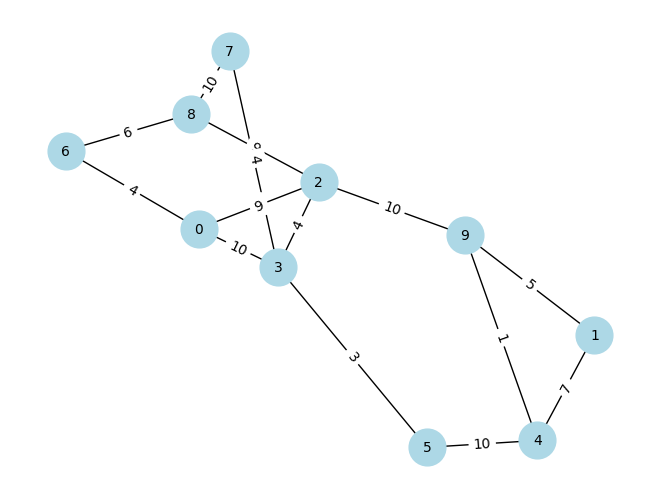

Choose the origin vertex:
0
1
2
3
4
5
6
7
8
9


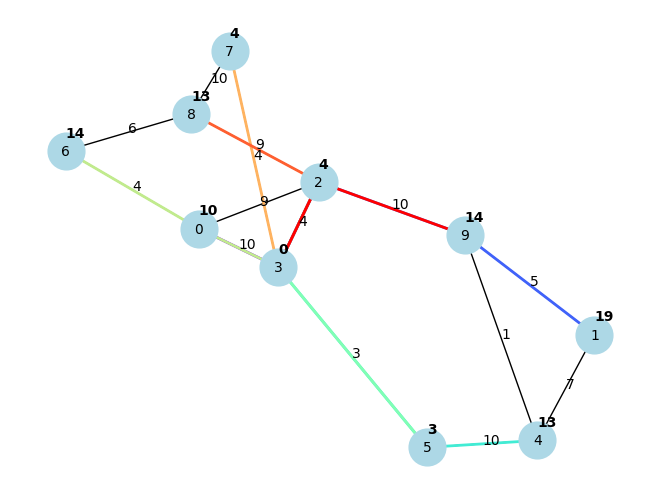

In [6]:
def generate_random_graph(n, p):
    # Uses the Erdos-Renyi model to generate a random graph
    # It generates a graph with n vertices and probability p of having an edge between two vertices
    G = nx.erdos_renyi_graph(n, p)
    for (u, v) in G.edges():
        G.edges[u, v]['weight'] = random.randint(1, 10)
    return G


def plot_graph(G, pos):
    nx.draw(G, pos, with_labels=True, node_size=700,
            font_size=10, node_color='lightblue')
    labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
    plt.show()


def choose_origin(G):
    print('Choose the origin vertex:')
    for v in G.nodes():
        print(v)
    origin = int(input())
    return origin


def dijkstra(G, origin):
    dist = {}
    for v in G.nodes():
        dist[v] = np.inf
    dist[origin] = 0
    pq = []
    heapq.heappush(pq, (0, origin))
    while pq:
        d, u = heapq.heappop(pq)
        for v in G.neighbors(u):
            if dist[v] > dist[u] + G.edges[u, v]['weight']:
                dist[v] = dist[u] + G.edges[u, v]['weight']
                heapq.heappush(pq, (dist[v], v))
    return dist


def plot_shortest_path(G, origin, dist, pos):
    nx.draw(G, pos, with_labels=True, node_size=700,
            font_size=10, node_color='lightblue')
    labels = nx.get_edge_attributes(G, 'weight')
    for (u, v), w in labels.items():
        plt.text((pos[u][0] + pos[v][0]) / 2, (pos[u][1] +
                 pos[v][1]) / 2, s=str(w), color='black')

    edges_in_path = []

    for v in G.nodes():
        if v != origin and dist[v] != np.inf:
            path = nx.shortest_path(G, origin, v, weight='weight')
            edges_in_path.append([(path[i], path[i + 1])
                                 for i in range(len(path) - 1)])

    colors = cm.rainbow(np.linspace(0, 1, len(edges_in_path)))

    for path, color in zip(edges_in_path, colors):
        nx.draw_networkx_edges(G, pos, edgelist=path,
                               edge_color=[color], width=2)

    for v in G.nodes():
        plt.text(pos[v][0], pos[v][1] + 0.05, s=str(dist[v]),
                 color='black', fontweight='bold')

    plt.show()


def main():
    G = generate_random_graph(10, 0.33)
    pos = nx.spring_layout(G)
    plot_graph(G, pos)
    origin = choose_origin(G)
    dist = dijkstra(G, origin)
    plot_shortest_path(G, origin, dist, pos)


if __name__ == '__main__':
    main()
